# Figure 7

In [3]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import sys
sys.path.append('../../../python_modules/')
plt.rcParams['figure.dpi'] = 200
plt.rcParams['pdf.fonttype'] = '42'

from domino.models.domino_models import DominoSingleOutput
from domino.utils import tools
from domino.data.domino_data import GenomeDataset
from domino.data.data import preprocess_data, process_bed_file_df
from domino.utils.tools import seq_from_df
import matplotlib.ticker as mticker
from generic_plotting_functions import *


import pandas as pd
import os
import numpy as np

import fanc
import fanc.plotting as fancplot

from domino.utils.plotting import plot_attribution

import coolbox
from coolbox.api import *

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Show example with nc14, larval, and adult brain boundaries

In [4]:
resolution=200
ws=1 # insulation window size
delta=2
demean_context_bin_width = 10 # insulation context window size
boundary_length=200
data_dir = '/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing'
genome_path = '/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/annotations/dm6.fa'
batch_size=32

tissue2mcool = dict()
tissue2bound = dict()
tissue2ins = dict()

def get_file(folder, tag):
    file = glob.glob(f'{folder}/*{tag}')
    assert (len(file) == 1)
    return file[0]

In [5]:
import glob

# MCOOL
tissue2mcool['nc14'] = get_file(f'{data_dir}/mcools/', 'new_nc14*11.mcool')
tissue2mcool['larval_brain'] = get_file(f'{data_dir}/mcools/', 'new_larval_CNS_merged.mcool')
tissue2mcool['adult_brain'] = get_file(f'{data_dir}/mcools/', 'adult_CNS_merged.mcool')

# INSULATION
tissue2ins['nc14'] = get_file(f'{data_dir}/insulations/insulation_files', 'new_nc14*11*1kb.bed')
tissue2ins['larval_brain'] = get_file(f'{data_dir}/insulations/insulation_files', 'new_larval_CNS_merged.resolution=200bp*1kb*.bed')
tissue2ins['adult_brain'] = get_file(f'{data_dir}/insulations/insulation_files', 'adult_CNS_merged.resolution=200bp*1kb*.bed')

# BOUNDARIES
tissue2bound['nc14'] = get_file(f'{data_dir}/boundaries', 'new_nc14*11*delta=2*1kb*.bed')
tissue2bound['larval_brain'] = get_file(f'{data_dir}/boundaries', 'new_larval_CNS_merged.resolution=200bp*delta=2*1kb*.bed')
tissue2bound['adult_brain'] = get_file(f'{data_dir}/boundaries', 'adult_CNS_merged.resolution=200bp*delta=2*1kb*.bed')


In [9]:
lb_ins_ws=1
mean_scaling_window=10
lb_ins_dir = "/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/insulations/insulation_files"
lb_ins1_path = f"{lb_ins_dir}/new_larval_CNS_merged.resolution=200bp.insulation_1kb.bed"
lb_ins_score1 = process_bed_file_df(lb_ins1_path, target_col='ins_score')
lb_ins_score1["demeaned_ins_score"] = lb_ins_score1["ins_score"] - lb_ins_score1["ins_score"].rolling(2*mean_scaling_window+1, center=True).mean()

In [32]:
def get_true_track(boundary, tissue, ins_score_context_bin_width=10, resolution=200, bp_radius=20_000):
    ins_ws=1
    ins_dir = "/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/insulations/insulation_files"
    ins1_path = tissue2ins[tissue]
    ins_score1 = process_bed_file_df(ins1_path, target_col='ins_score')
    
    # get insulation around boundary of interest
    chrom, start, end = boundary
    tmp = ins_score1.query('chrom == @chrom and start == @start and end==@end')
    bin_radius = bp_radius // resolution
    locus_df = ins_score1.iloc[tmp.index.item() - bin_radius:tmp.index.item() + bin_radius + 1]
    
    ins_score_context_bin_width=10
    idxs_pos = np.array([np.arange(i-ins_score_context_bin_width, i+ins_score_context_bin_width+1) for i in locus_df.index])
    y_pos = np.array([np.array(ins_score1['ins_score'][idx_arr]) for idx_arr in idxs_pos]) # context with middle bin
    
    demeaned_y1_pos = y_pos - np.nanmean(y_pos, axis=1)[:, np.newaxis]
    middle_points1_pos = demeaned_y1_pos[:, ins_score_context_bin_width]

    x, y = np.arange(len(middle_points1_pos)), middle_points1_pos

    # replace all non finite with 0 for visualization purposes 
    y[~np.isfinite(y)] = 0
    return x, y

def save_track(y, boundary, fn, resolution=200, offset=20_000):
    chrom, start, end = boundary
    df = pd.DataFrame({
        'chrom': [chrom] * len(y),
        'start': np.arange(start - offset, end + offset, resolution),
        'end': np.arange(start - offset, end + offset, resolution) + resolution,
        'value': y
    })
    df["value"] = pd.to_numeric(df["value"], errors="coerce")
    df.to_csv(fn, sep='\t', header=False, index=False)
    return df

[ERROR:tab.py:300 -                query()] Reference sequence chr3L not found in index header.


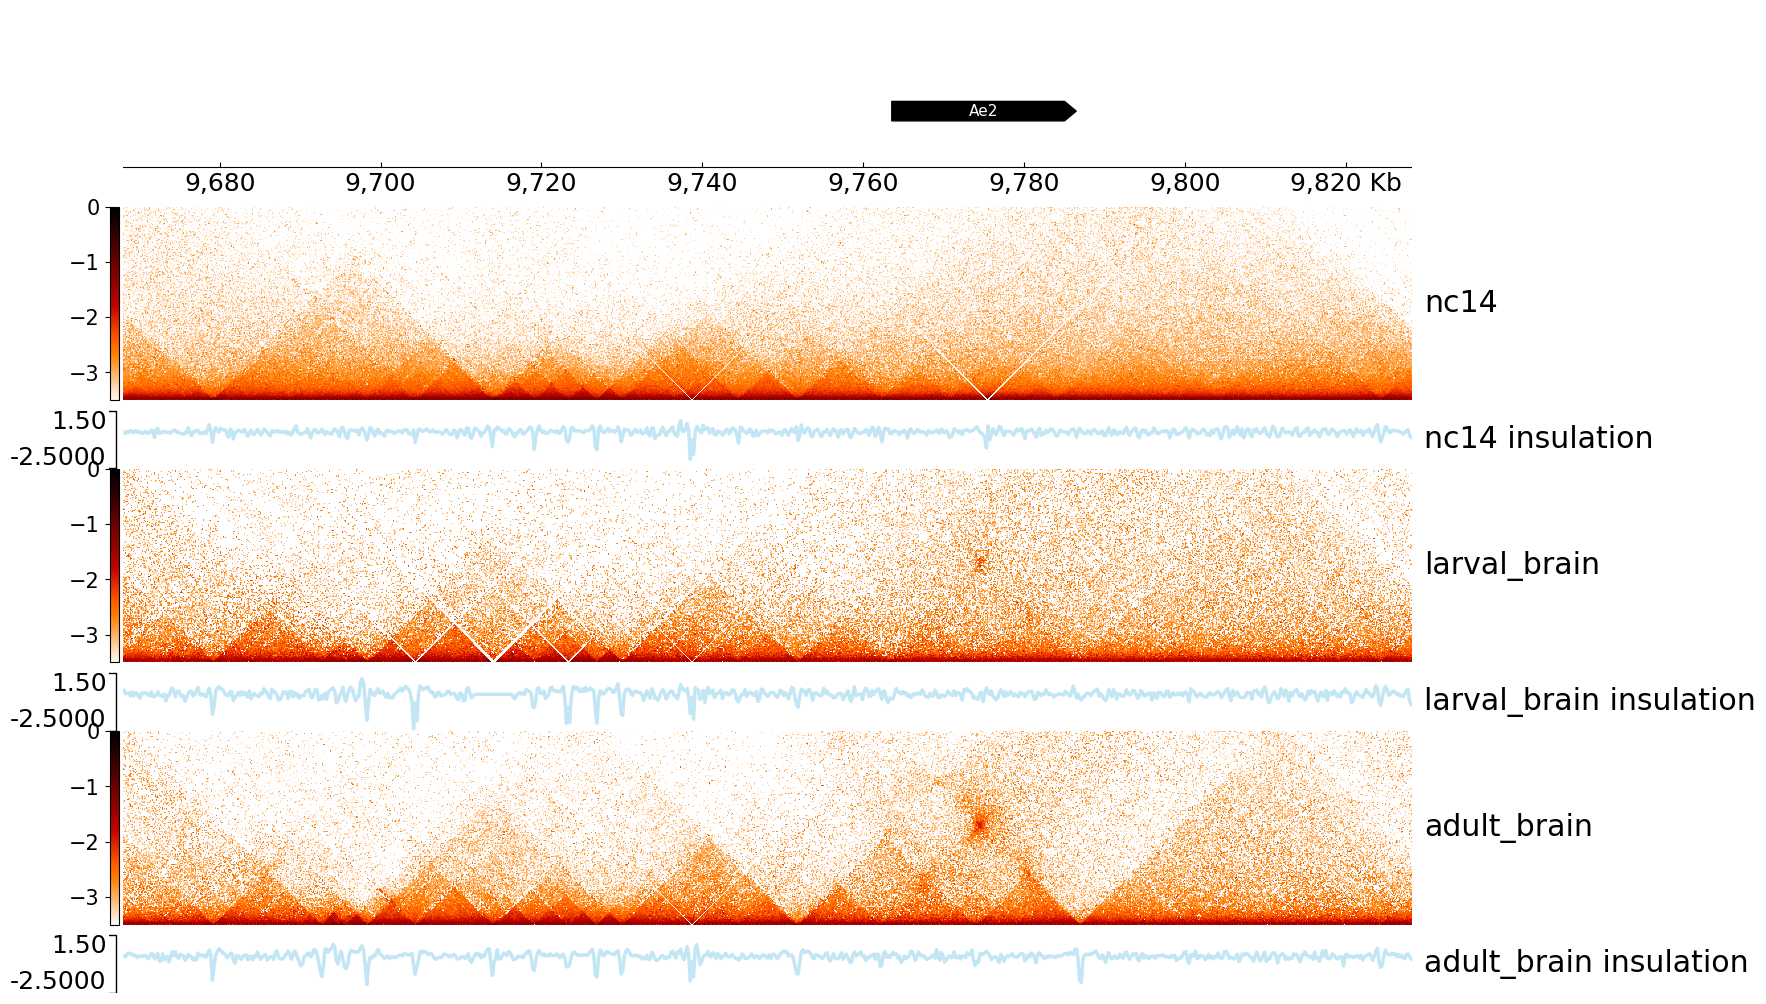

In [34]:
boundary = ("chr3L", 9748001, 9748200)

# for tissue in tissue2ins:
#     _, obs_y = get_true_track(boundary, tissue, bp_radius=80_000)
#     print(obs_y.shape)
#     obs_df = save_track(obs_y, boundary, f'{tissue}_insulation_track.bedGraph', offset=80_000)

plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['font.size'] = 18

RESOLUTION=200
NUM_MERGED=11

chrom, start, end = "chr3L", 9748001, 9748200

HIC_KWARGS = dict(
    style='window', 
    resolution=200, 
    depth_ratio=0.3, 
    cmap='gist_heat_r', 
    norm='no', 
    transform='log10', 
    max_value=0, 
    min_value=-3.5, 
    grid=False,
)

BEDGRAPH_KWARGS = dict(
    border_only=True,
    labels=False,
    num_rows=1,
    linewidth=4,
    height=1.5,
    style='line',
    line_width=2.5,
    alpha=0.5,
    min_value=-2.5,
    max_value=1.5,
    border_color=None,
    properties=dict(fontsize=16),
)

BED_KWARGS = dict(
    border_only=False,
    labels=True,
    num_rows=1,
    linewidths=1,
    fontsize=1,
    height=1,
    properties=dict(line_width=1, fontsize=1, size=1),
    border_color=None,
    marker='.'
)

frame = []
frame.extend([coolbox.api.GTF('/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/annotations/Drosophila_melanogaster.BDGP6.54.115.gtf',
                                                    row_filter="type == 'gene';feature_name == 'Ae2'", color="#000000"), TrackHeight(3)])
frame.extend([coolbox.api.XAxis(fontsize=18, show_chrom=True)])
for tissue in tissue2mcool.keys():
    frame.extend(
        [
            # Map
            coolbox.api.HiCMat(tissue2mcool[tissue], title=tissue, **HIC_KWARGS),
            coolbox.api.Spacer(), coolbox.api.TrackHeight(0.25),
                        
            # Insulation tracks
            coolbox.api.BedGraph(f'{tissue}_insulation_track.bedGraph', title=f'{tissue} insulation', color="skyblue",  **BEDGRAPH_KWARGS),
        ]
    )
from functools import reduce

frame = reduce(lambda x, y: x + y, frame)
fig = frame.plot(f"{chrom}:{start-80_000}-{end + 80_000}")
fig.set(facecolor="white")
fig.savefig("plots/locus_different_tissues.pdf", format="pdf")
display(fig)

## Filter boundaries based on stripes and NaN region

In [35]:
ws = 1

# get all boundaries at nc14, larval and adult brain
nc14_model_dir = '/scratch/gpfs/PRITYKIN/brendan/domino/output/06_12_2026_final_nc14_no_mig/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/'
larval_model_dir = '/scratch/gpfs/PRITYKIN/brendan/domino/output/02_27_2026_final_larval_brain/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/'
adult_model_dir = '/scratch/gpfs/PRITYKIN/brendan/domino/output/06_13_2025_adult_brain/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/'

nc14_ins_path = f'/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/insulations/insulation_files/new_nc14_embryo_merged_all_11.resolution=200bp.insulation_{ws}kb.bed'
nc14_ins = process_bed_file_df(nc14_ins_path, 'ins_score')
nc14_bound_df = pd.read_csv(f'{nc14_model_dir}/final_nc14_boundaries_df.bound_score_gt_1.csv')

larval_brain_ins_path = f'/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/insulations/insulation_files/new_larval_CNS_merged.resolution=200bp.insulation_{ws}kb.bed'
larval_brain_ins = process_bed_file_df(larval_brain_ins_path, 'ins_score')
larval_bound_df = pd.read_csv(f'{larval_model_dir}/final_boundaries_df.bound_score_gt_1.2.nan_offset=20000.stripe_offset=800.csv')

adult_brain_ins_path = f'/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/insulations/insulation_files/adult_CNS_merged.resolution=200bp.insulation_{ws}kb.bed'
adult_brain_ins = process_bed_file_df(adult_brain_ins_path, 'ins_score')
adult_bound_df = pd.read_csv(f'{adult_model_dir}/final_boundaries_df.bound_score_gt_1.4.nan_offset=20000.stripe_offset=800.csv')

In [37]:
import pandas as pd

nc14_bound_df = nc14_bound_df.query('has_stripe_at_bound == False')
larval_bound_df = larval_bound_df.query('has_stripe_at_bound == False')
adult_bound_df = adult_bound_df.query('has_stripe_at_bound == False')

def rename_cols(df):
    df = df.rename(columns={
        "Chromosome": "chrom",
        "Start": "start",
        "End": "end"
    })
    return df

df1_exp = nc14_bound_df
df2_exp = larval_bound_df
df3_exp = adult_bound_df
    
union_df = pd.concat([df1_exp, df2_exp, df3_exp], ignore_index=True)[["chrom", "start", "end"]].drop_duplicates()

# Boolean columns indicating if interval is in each df
union_df["in_nc14"] = union_df.apply(
    lambda r: ((df1_exp["chrom"] == r.chrom) & (df1_exp["start"] == r.start) & (df1_exp["end"] == r.end)).any(),
    axis=1
)

union_df["in_larval_brain"] = union_df.apply(
    lambda r: ((df2_exp["chrom"] == r.chrom) & (df2_exp["start"] == r.start) & (df2_exp["end"] == r.end)).any(),
    axis=1
)

union_df["in_adult_brain"] = union_df.apply(
    lambda r: ((df3_exp["chrom"] == r.chrom) & (df3_exp["start"] == r.start) & (df3_exp["end"] == r.end)).any(),
    axis=1
)

union_df.reset_index(drop=True, inplace=True)

In [41]:
# mean scaling - "." means it's NaN
mean_scaling_window=10
nc14_ins["demeaned_ins_score"] = nc14_ins["ins_score"] - nc14_ins["ins_score"].rolling(2*mean_scaling_window+1, center=True).mean()
larval_brain_ins["demeaned_ins_score"] = larval_brain_ins["ins_score"] - larval_brain_ins["ins_score"].rolling(2*mean_scaling_window+1, center=True).mean()
adult_brain_ins["demeaned_ins_score"] = adult_brain_ins["ins_score"] - adult_brain_ins["ins_score"].rolling(2*mean_scaling_window+1, center=True).mean()

In [42]:
def get_demeaned_ins_track(row, ins, ins_score_context_bin_width=10, OFFSET=2000, boundary_length=200):
    """
    Get true insulation track centered on a example of interest. The default is 4.2 Kb region.
    """
    chrom, start, end = row.chrom, row.start, row.end
    # get insulation around boundary of interest
    tmp = ins.query('chrom == @chrom and start == @start and end==@end')
    i = tmp.index.item()
    idxs_pos = np.arange(i-ins_score_context_bin_width, i+ins_score_context_bin_width+1)
    y_pos = np.array([np.array(ins['demeaned_ins_score'][idx_arr]) for idx_arr in idxs_pos]) # context with middle bin
    return y_pos

# from tqdm import tqdm
# nc14_demean_ins_tracks = []
# larval_demean_ins_tracks = []
# adult_demean_ins_tracks = []
# for _, row in tqdm(union_df.iterrows(), total=len(union_df)):
#     nc14_demean_ins_tracks.append(get_demeaned_ins_track(row, nc14_ins))
#     larval_demean_ins_tracks.append(get_demeaned_ins_track(row, larval_brain_ins))
#     adult_demean_ins_tracks.append(get_demeaned_ins_track(row, adult_brain_ins))

# np.save('new_adult_ins_arr_at_stripe_filtered_boundaries.npy', np.array(adult_demean_ins_tracks))
# np.save('new_larval_ins_arr_at_stripe_filtered_boundaries.npy', np.array(larval_demean_ins_tracks))
# np.save('new_nc14_ins_arr_at_stripe_filtered_boundaries.npy', np.array(nc14_demean_ins_tracks))

adult_demeaned_arr = np.load('new_adult_ins_arr_at_stripe_filtered_boundaries.npy')
larval_demeaned_arr = np.load('new_larval_ins_arr_at_stripe_filtered_boundaries.npy')
nc14_demeaned_arr = np.load('new_nc14_ins_arr_at_stripe_filtered_boundaries.npy')

In [44]:
# sort by center local insulation of nc14 
mid = nc14_demeaned_arr.shape[1] // 2  # index 10

BIN_RADIUS=0
middle_sum = nc14_demeaned_arr[:, mid-BIN_RADIUS:mid+BIN_RADIUS+1].sum(axis=1) 

sorted_indices = np.argsort(middle_sum)
nc14_arr_sorted = nc14_demeaned_arr[sorted_indices]
larval_arr_sorted = larval_demeaned_arr[sorted_indices]
adult_arr_sorted = adult_demeaned_arr[sorted_indices]

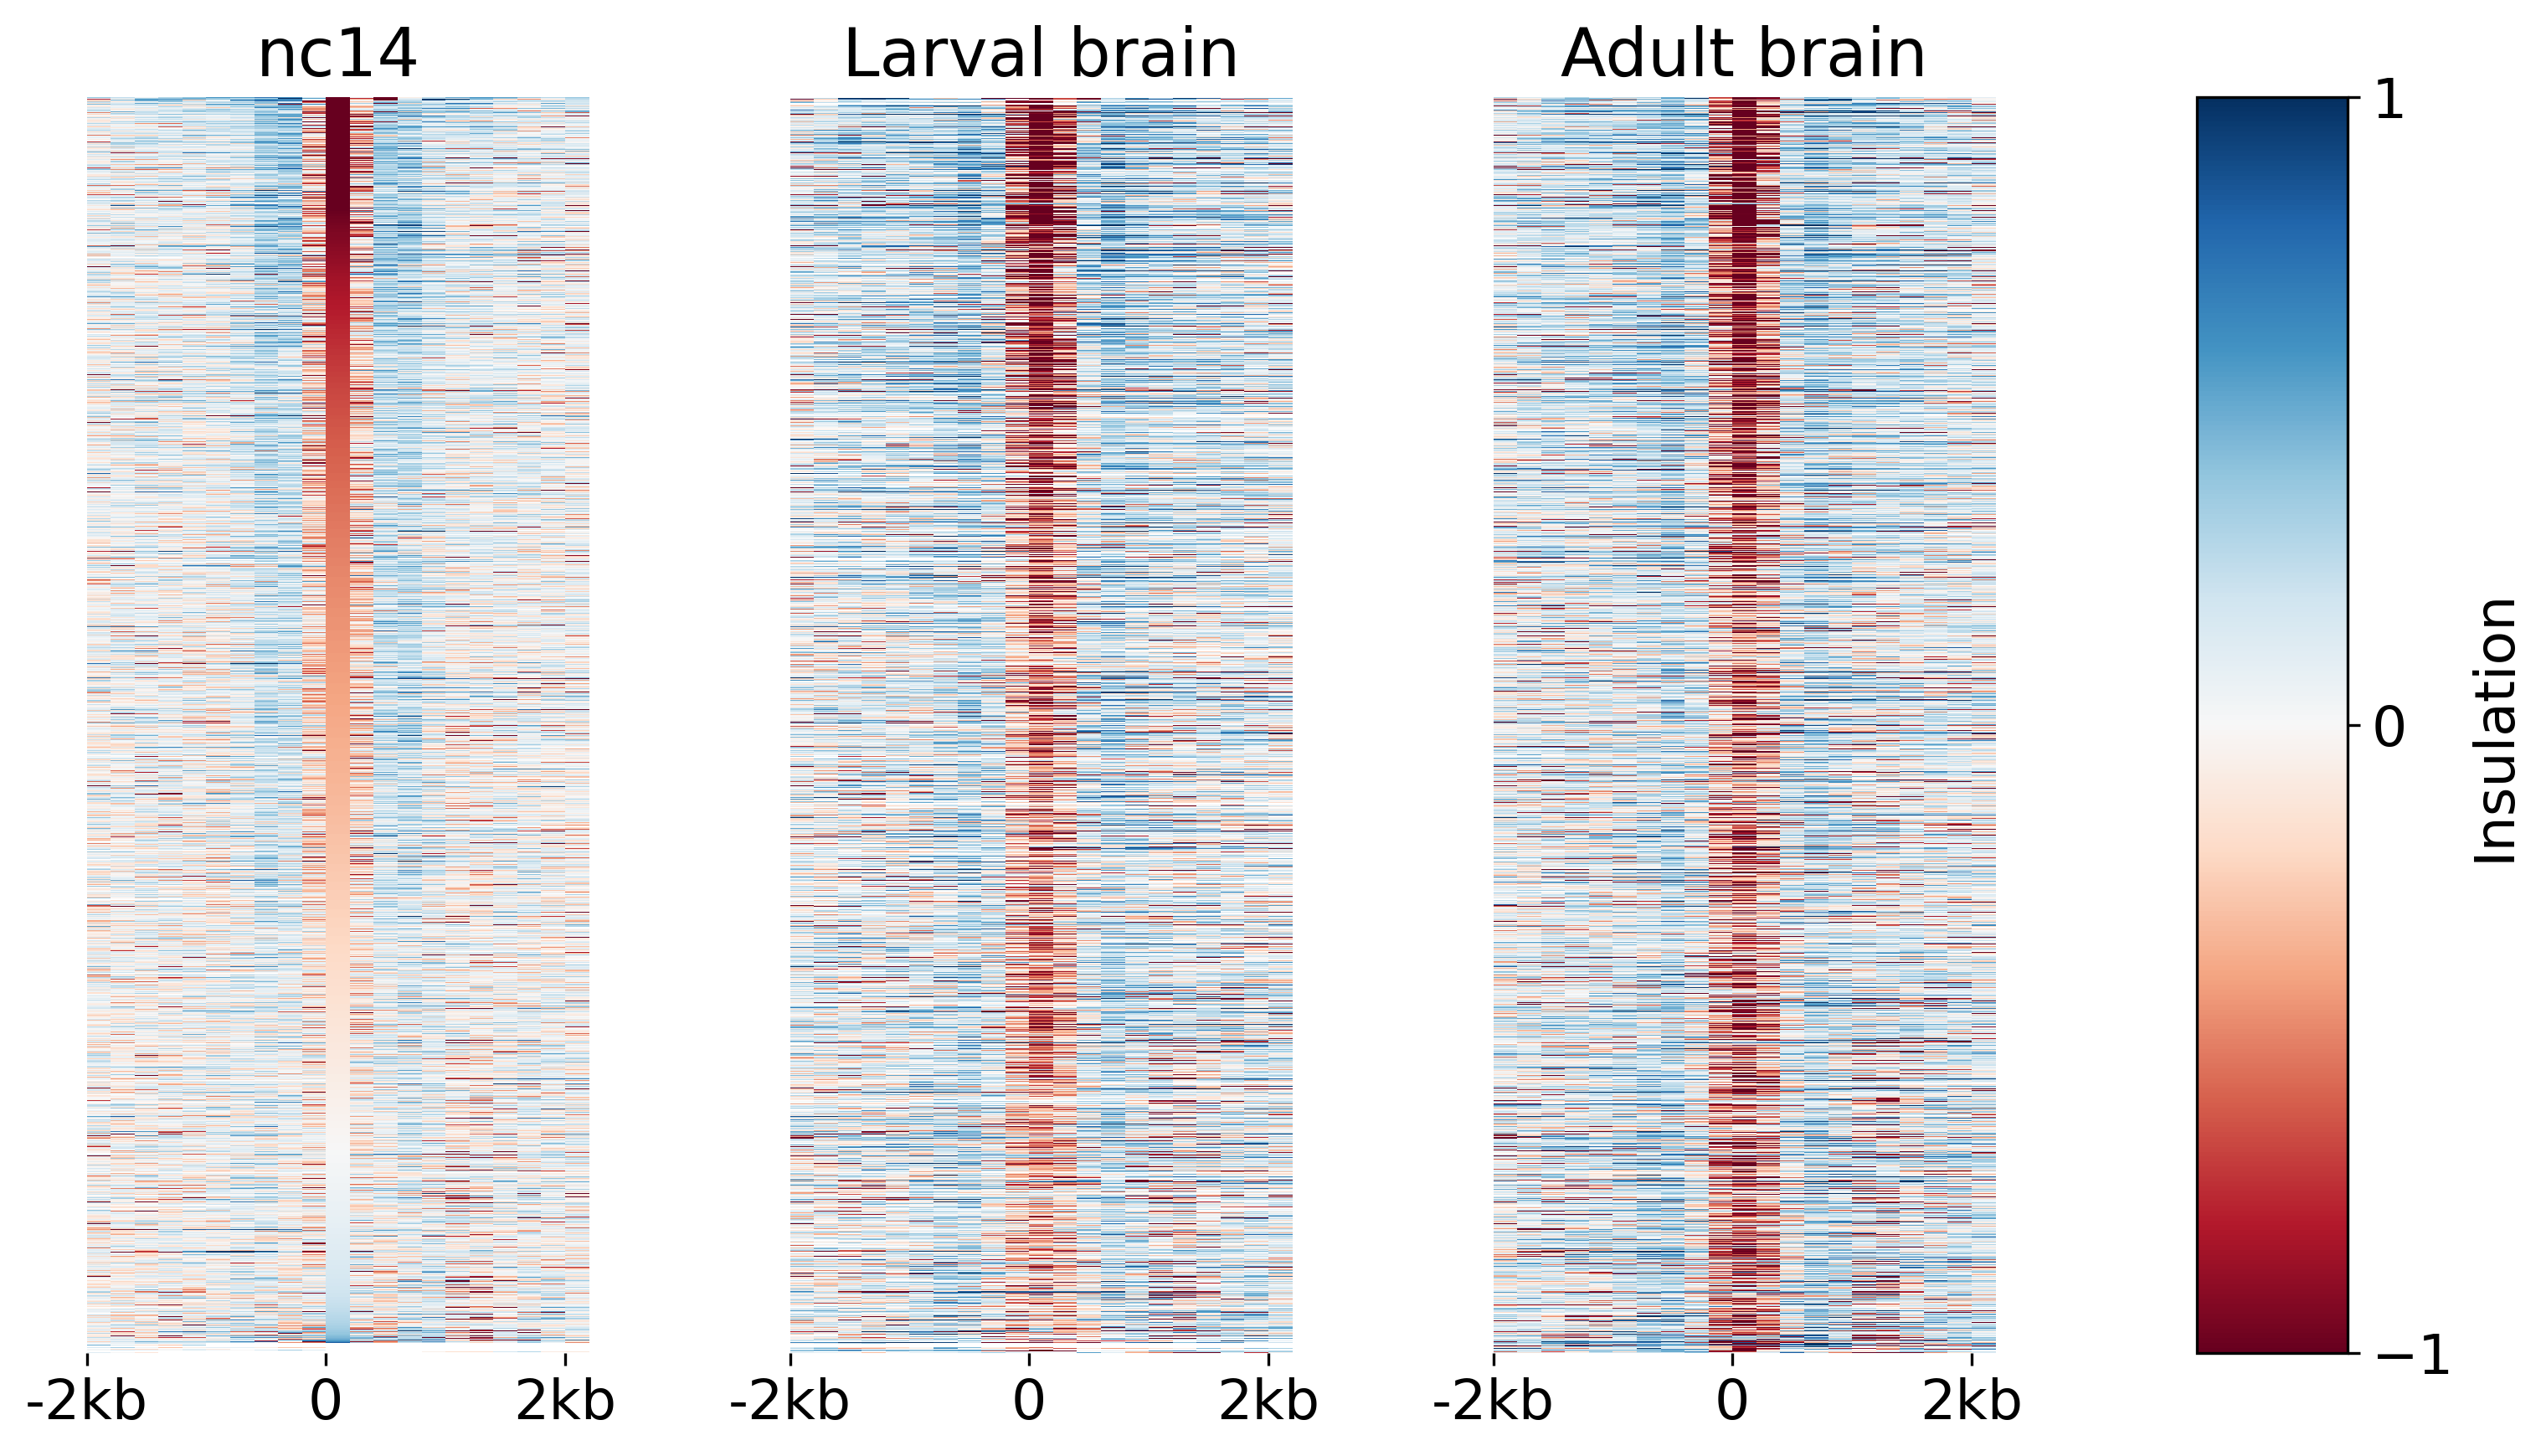

In [45]:
import seaborn as sns

plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['font.size'] = 16

fig, axes = init_subplots_exact(4, 1, fgsz=(2,5), x_ratios=[1,1,1,0.3], xspace=1.4, dpi=300)
cax = axes[3]

common_kwargs = dict(cmap='RdBu', center=0, cbar_kws={"label": "Local insulation", "shrink": 0.5, "ticks":[-1,0,1]})

masks = [~np.isfinite(arr) for arr in (nc14_arr_sorted, larval_arr_sorted, adult_arr_sorted)]

tick_positions = [0, 10, 20]        # indices
tick_labels = ['-2kb', '0', '2kb']  # your labels

for i, (arr, mask, ax, title) in enumerate(zip([nc14_arr_sorted, larval_arr_sorted, adult_arr_sorted], masks, axes[:3], ["nc14", "Larval brain", "Adult brain"])):
    hm = sns.heatmap(arr, ax=ax, mask=mask, **common_kwargs, cbar=False, vmin=-1, vmax=1, rasterized=True)
    ax.set_title(title)
    
    # Hide y-axis
    ax.set_yticks([])
    ax.set_ylabel('')
    ax.tick_params(left=False)
    
    ax.set_xlabel('')
    ax.set_xticks(tick_positions)
    ax.set_xticklabels(tick_labels)

fig.colorbar(
    hm.collections[0],  # use last heatmap's mappable
    cax=cax,
    ticks=[-1, 0, 1],
    shrink=0.5
)
cax.set_ylabel("Insulation")
# fig.savefig("plots/insulation_tornado_plots.pdf", format="pdf", dpi=300, bbox_inches='tight')
plt.show()

## Full list of motifs

In [46]:
from load_modisco import *
import json

TFMODISCO_WINDOW=600
NUM_FLANKING_BASES=4

def get_final_df(pattern_cwms):
    """
    Given CWMs, return info about each motif, including average per-bp attribution.
    """
    # given CWM patterns, get the average 
    avg_attrs = []
    num_seqlets = []
    for name, cwm in pattern_cwms.items():
        assert(round(cwm['fwd'].mean(), 5) == round(cwm['rev'].mean(), 5))
        avg_attrs.append(cwm['fwd'].sum()/cwm['fwd'].shape[0])
        num_seqlets.append(cwm['num_seqlets'])

    average_attr_df = pd.DataFrame({'name': pattern_cwms.keys(), 'avg_attr': avg_attrs, 'num_seqlets': num_seqlets})
    pattern_df = average_attr_df.sort_values('avg_attr')
    return pattern_df

def get_pattern_cwms(out_folder, TFMODISCO_WINDOW, num_flanking_bases=4):
    h5_file = f"{out_folder}/modisco_results_{TFMODISCO_WINDOW}bp.h5"
    pattern_cwms, pattern_pwms = get_pattern_info(h5_file, num_flanking_bases=num_flanking_bases)
    return pattern_cwms
    
def get_pattern_attr(out_folder, TFMODISCO_WINDOW, pattern2target_file, num_flanking_bases=4):
    """
    Get full pattern DF with match annotations.
    """
    h5_file = f"{out_folder}/modisco_results_{TFMODISCO_WINDOW}bp.h5"
    pattern_cwms, pattern_pwms = get_pattern_info(h5_file, num_flanking_bases=num_flanking_bases)
    pattern_df = get_final_df(pattern_cwms)
    pattern_df = pattern_df.query('name.str.contains("neg")')

    with open(pattern2target_file, 'r') as f:
        npatterns2targets = json.load(f)

    tmp = []
    for i, p in enumerate(pattern_df.name):
        if p in npatterns2targets:
            if isinstance(npatterns2targets[p], list):
                tmp.append(npatterns2targets[p][0])    
            else:
                tmp.append(npatterns2targets[p])
        else:
            tmp.append('UM' + str(i))
    pattern_df['target'] = tmp
    
    return pattern_df

nc14_pattern_df = get_pattern_attr(nc14_model_dir + '/ism_report_1_cutoff/', TFMODISCO_WINDOW,
                                  "/scratch/gpfs/PRITYKIN/brendan/domino/notebook/figures_rerun/fig2_motif_discovery/all_nc14_pattern_to_target_dict.json",
                                  num_flanking_bases=NUM_FLANKING_BASES)
larval_brain_pattern_df = get_pattern_attr(larval_model_dir + '/ism_report/', TFMODISCO_WINDOW,
                                          "/scratch/gpfs/PRITYKIN/brendan/domino/notebook/figures_cleaned/fig6/neg_pattern_to_target_dict_larval.json",
                                          num_flanking_bases=NUM_FLANKING_BASES)
adult_brain_pattern_df = get_pattern_attr(adult_model_dir + '/ism_report/', TFMODISCO_WINDOW,
                                         "/scratch/gpfs/PRITYKIN/brendan/domino/notebook/figures_cleaned/fig6/neg_pattern_to_target_dict_adult.json",
                                         num_flanking_bases=NUM_FLANKING_BASES)

In [47]:
# 4 flankimg base pairs
nc14_pattern_cwms = get_pattern_cwms(nc14_model_dir + '/ism_report_1_cutoff/', TFMODISCO_WINDOW=600,num_flanking_bases=4)
larval_brain_pattern_cwms = get_pattern_cwms(larval_model_dir + '/ism_report/',TFMODISCO_WINDOW=600, num_flanking_bases=4) 
adult_brain_pattern_cwms = get_pattern_cwms(adult_model_dir + '/ism_report/', TFMODISCO_WINDOW=600,num_flanking_bases=4)

def compute_ic(cwm):
    # Normalize columns to probabilities
    probs = cwm / np.sum(cwm, axis=0, keepdims=True)
    with np.errstate(divide='ignore', invalid='ignore'):
        ic = 2 + np.nansum(probs * np.log2(probs), axis=0)
    return np.sum(ic)  # or np.mean(ic) for mean per position

def plot_weights(array, ax, pattern_name=None, num_seqlets=None, q_val=None):
    """
    Copied from https://github.com/jmschrei/tfmodisco-lite/blob/main/modiscolite/report.py#L179.
    """
    df = pd.DataFrame(array, columns=['A', 'C', 'G', 'T'])
    df.index.name = 'pos'

    crp_logo = logomaker.Logo(df, ax=ax)
    crp_logo.style_spines(visible=False)
    crp_logo.style_spines(visible=False)
    ax.set_axis_off()
    if pattern_name and num_seqlets:
        ax.set_title(f'{pattern_name} {num_seqlets} {"{:.3e}".format(qval)}')

def compute_per_position_ic(ppm, background, pseudocount):
    """
    Copied from https://github.com/jmschrei/tfmodisco-lite/blob/main/modiscolite/report.py#L179.
    """
    alphabet_len = len(background)
    ic = ((np.log((ppm+pseudocount)/(1 + pseudocount*alphabet_len))/np.log(2))
          *ppm - (np.log(background)*background/np.log(2))[None,:])
    return np.sum(ic,axis=1)

def make_logo(ppm):
    """
    Copied from https://github.com/jmschrei/tfmodisco-lite/blob/main/modiscolite/report.py#L179.
    """
    background = np.array([0.29, 0.21, 0.21, 0.29])
    ic = compute_per_position_ic(ppm, background, 0.001)
    return ppm*ic[:, None]

import logomaker 

plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams['pdf.fonttype'] = 42
%matplotlib inline

motifs_of_interest = ['GAGA', 'Lola-N', 'Lola-I', 'Vostok', 'GTG2', 'Mulberry']

def plot_cwm_table(target_df, pattern_cwms, save_path, TOP_N=7, MIN_NUM_SEQLETS=100):
    
    df = target_df.query('num_seqlets > @MIN_NUM_SEQLETS and target.isin(@motifs_of_interest)').reset_index(drop=True)
    fig, axes = plt.subplots(len(df) + 1, 4, figsize=(25, len(df)*3), width_ratios=[0.5] * 4)
    for i, row in df.iterrows():
        i = i+1
        print(row.iloc[0])
        name = row.iloc[0]
        num_seqlets = row.num_seqlets
        target = row.target
        max_val = 0
        min_val = -0.12
        avg_attr = row['avg_attr']
    
        cwm = pattern_cwms[name]
        trimmed_cwm_fwd = cwm['fwd'] * -1

        if row.target == "GAGA" and row.num_seqlets != 3711 or row.num_seqlets == 2989:
            trimmed_cwm_fwd = cwm['rev'] * -1
        if row.target == "GTG2" and row.num_seqlets == 452:
            trimmed_cwm_fwd = cwm['rev'] * -1
        print(row.target, row.num_seqlets)
        if row.target == "Lola-N" and row.num_seqlets == 236:
            trimmed_cwm_fwd = cwm['rev'] * -1
        if row.target == "Lola-I" and row.num_seqlets == 924:
            trimmed_cwm_fwd = cwm['rev'] * -1
            
        plot_weights(trimmed_cwm_fwd, axes[i][0])
    
        for j in [1,3]:
            axes[i][j].imshow([[0]], cmap='Greys', vmin=0, vmax=1)
        for j in [1,2,3]:
            axes[i][j].set_xticks([])
            axes[i][j].set_yticks([])
            for spine in axes[i][j].spines.values():
                spine.set_visible(False)
        axes[i][2].imshow([[avg_attr]], cmap='Reds_r', vmin = min_val, vmax = max_val, aspect='equal', alpha=0.9)  # 1x1 square
        axes[i][1].text(0, 0, num_seqlets, ha='center', va='center', fontsize=50)
        axes[i][3].text(0, 0, target, ha='center', va='center', fontsize=50)
        
    headers = ['CWM', 'Seqlet count', 'Contribution', 'Motif']
    for j, header in enumerate(headers):
        axes[0][j].imshow([[0]], cmap='Greys', vmin=0, vmax=1)
        axes[0][j].text(0, 0, header, ha='center', va='center', fontsize=50)
        axes[0][j].set_xticks([])
        axes[0][j].set_yticks([])
        for spine in axes[0][j].spines.values():
            spine.set_visible(False)
    fig.savefig(save_path, format="pdf", dpi=300, bbox_inches='tight')
    plt.show()

neg_patterns.pattern_3
Lola-I 2374
neg_patterns.pattern_16
Vostok 773
neg_patterns.pattern_24
GTG2 452
neg_patterns.pattern_36
Mulberry 156
neg_patterns.pattern_1
GAGA 3711
neg_patterns.pattern_30
Lola-N 236


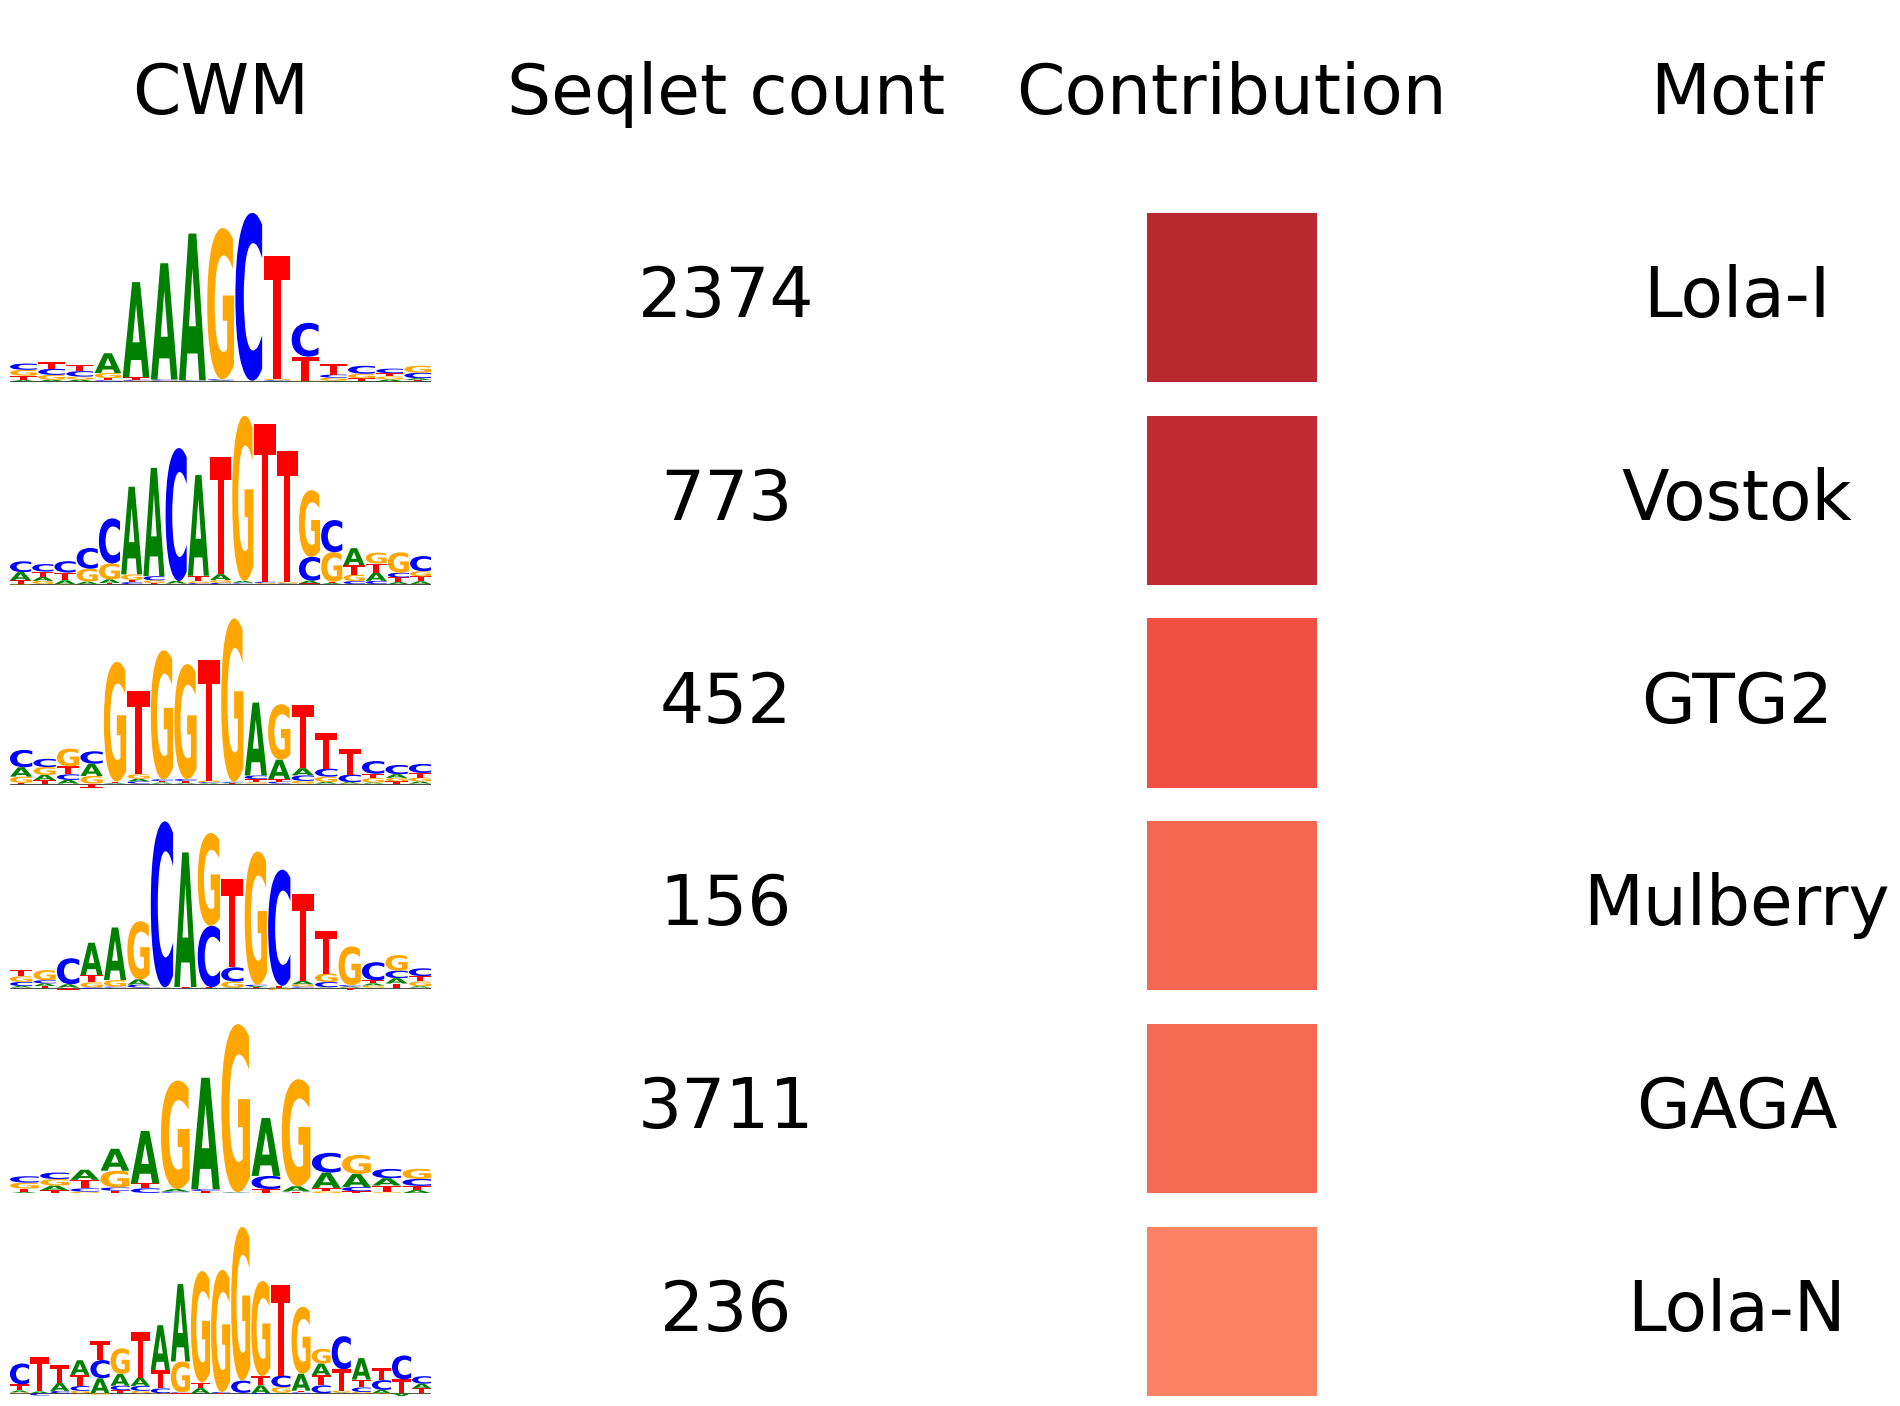

In [48]:
plot_cwm_table(adult_brain_pattern_df, adult_brain_pattern_cwms, "plots/adult_brain_cwm_table.pdf")

neg_patterns.pattern_19
Mulberry 284
neg_patterns.pattern_10
Lola-I 924
neg_patterns.pattern_15
GTG2 334
neg_patterns.pattern_17
Vostok 298
neg_patterns.pattern_11
Lola-N 786
neg_patterns.pattern_2
GAGA 2989


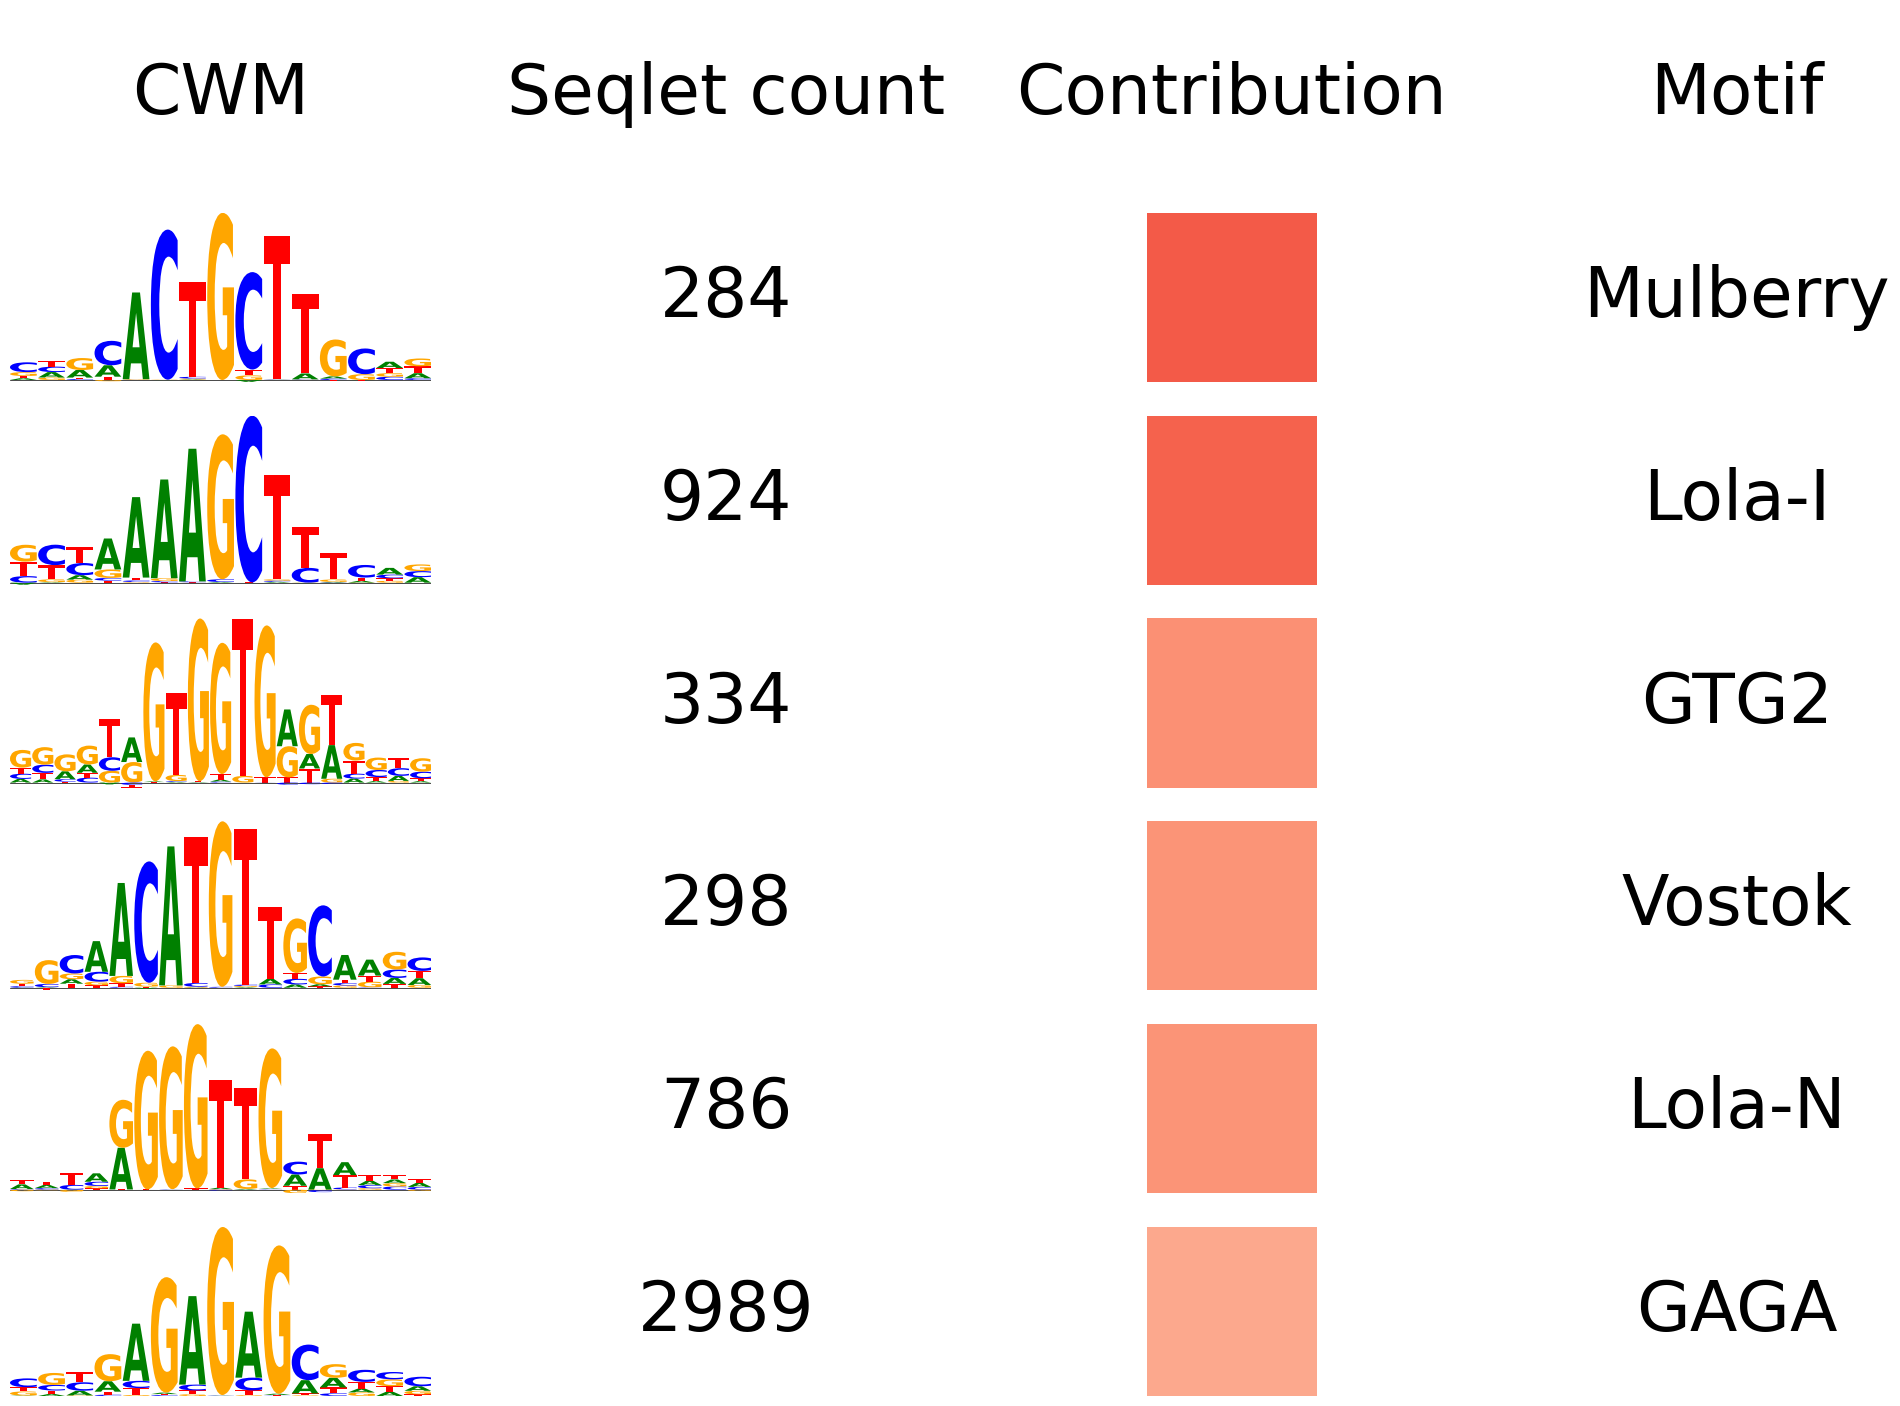

In [49]:
plot_cwm_table(larval_brain_pattern_df, larval_brain_pattern_cwms, "plots/larval_brain_cwm_table.pdf")

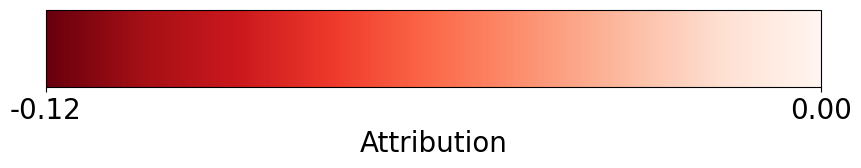

In [51]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors

MIN_NUM_SEQLETS = 100

%matplotlib inline

vmin = -0.12
vmax = 0
norm = mcolors.Normalize(vmin=vmin, vmax=vmax)
sm = cm.ScalarMappable(cmap='Reds_r', norm=norm)
sm.set_array([])
fig, ax = plt.subplots(figsize=(10,1))
cbar = fig.colorbar(sm, cax=ax, ticks=[vmin, vmax], orientation='horizontal', fraction=0.001,
    pad=0.1)
cbar.ax.set_xticklabels([f"{vmin:.2f}", f"{vmax:.2f}"], fontsize=20)
cbar.set_label("Attribution", fontsize=20)

# plt.savefig("plots/brain_tissue_colorbar.pdf", format="pdf", dpi=300, bbox_inches='tight')
plt.show()

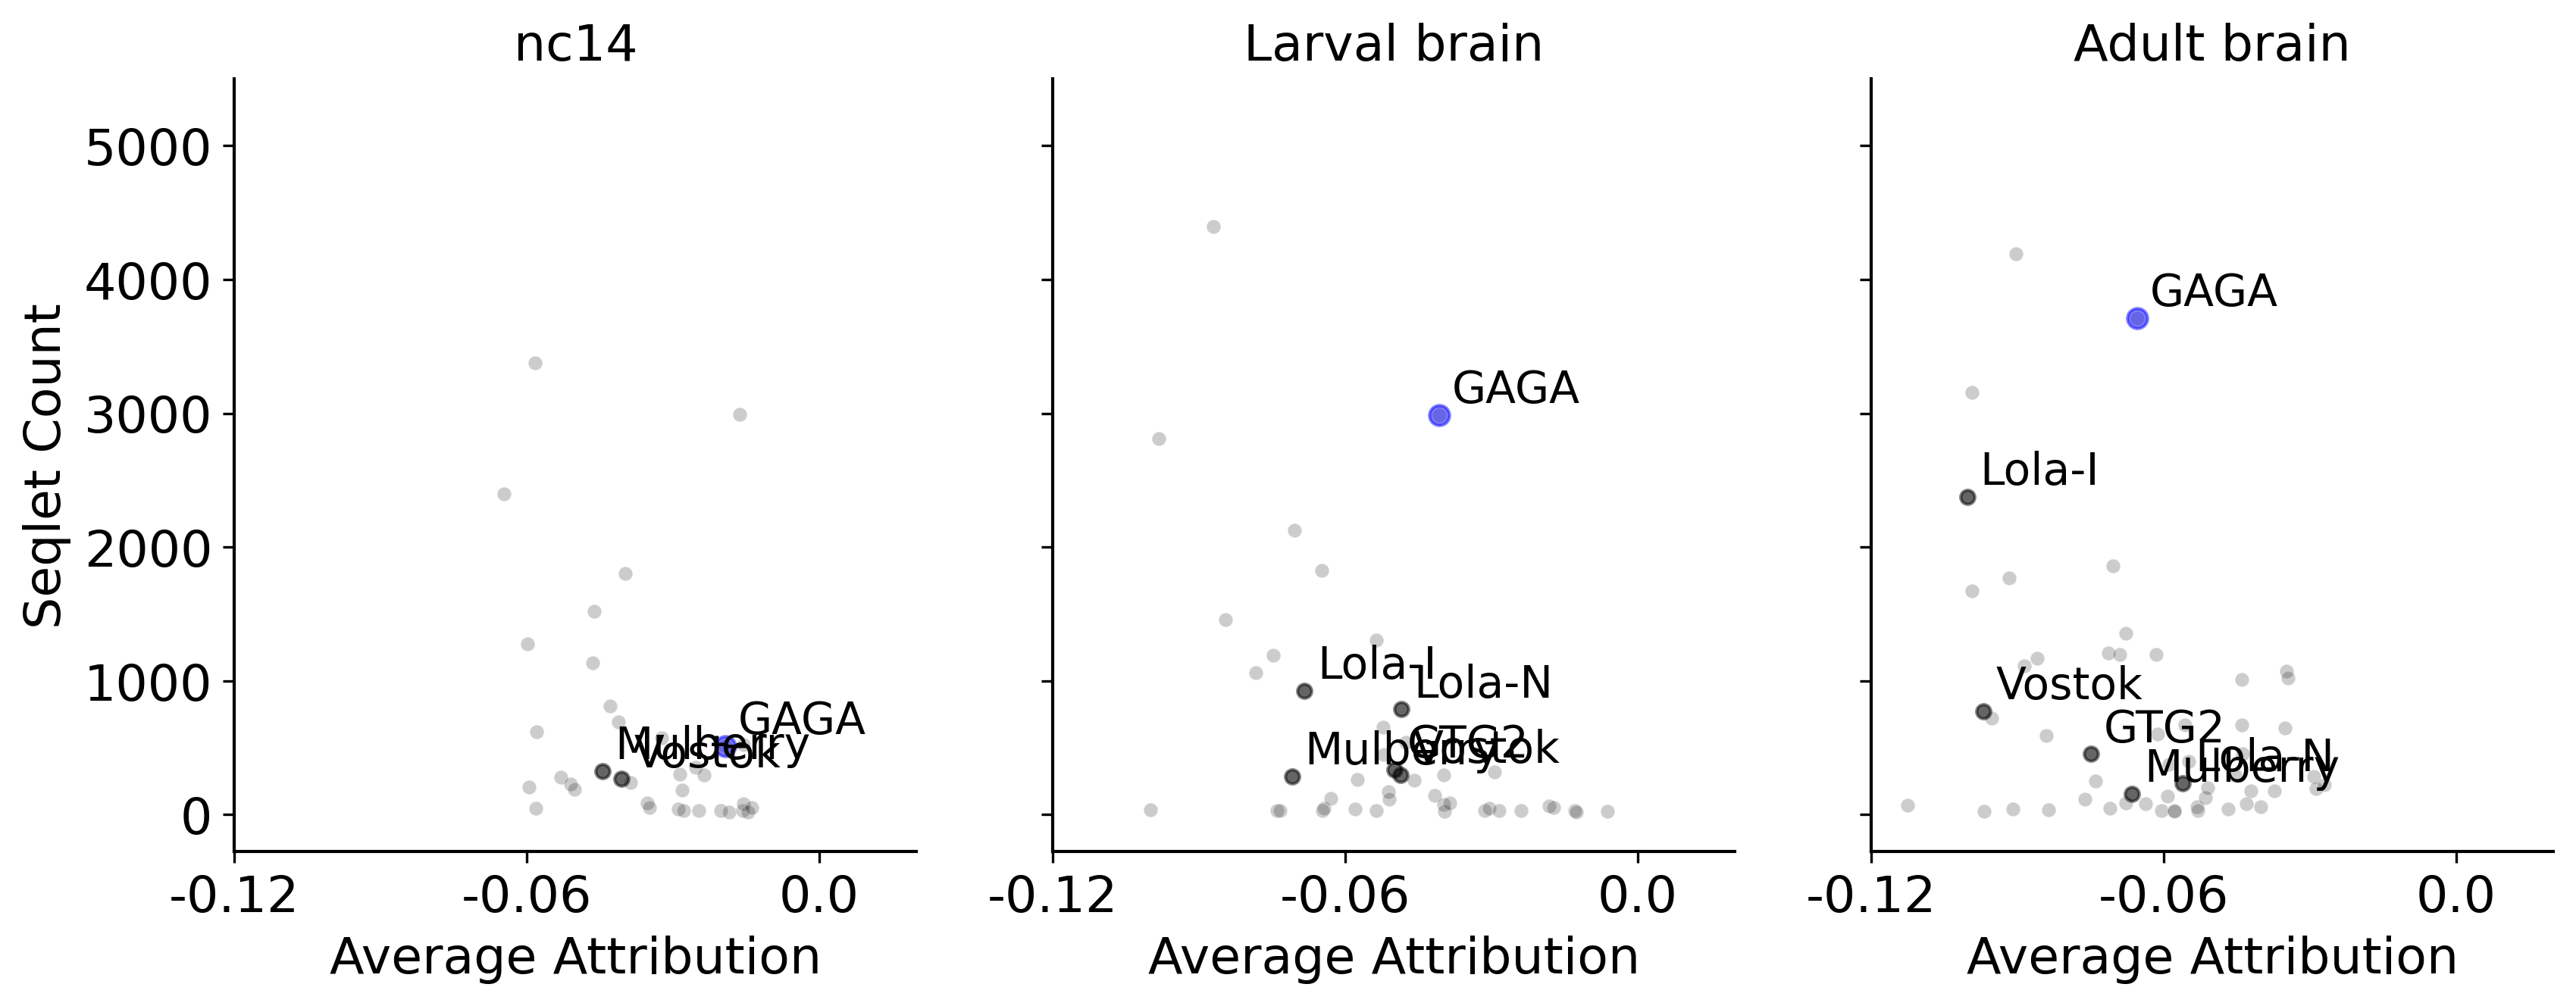

In [52]:
plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['font.size'] = 16

fig, axs = init_subplots_exact(3,1, sharey=True, dpi=300, x_ratios = [0.75, 0.75, 0.75], y_ratios=[0.85], sharex=1.2)
sns.scatterplot(nc14_pattern_df, x='avg_attr', y='num_seqlets', s=20, c='black', alpha=0.2, ax=axs[0])
sns.scatterplot(larval_brain_pattern_df, x='avg_attr', y='num_seqlets', s=20, c='black', alpha=0.2,ax=axs[1])
sns.scatterplot(adult_brain_pattern_df, x='avg_attr', y='num_seqlets', s=20, c='black', alpha=0.2, ax=axs[2])

for i, df in enumerate([nc14_pattern_df, larval_brain_pattern_df, adult_brain_pattern_df]):
    mask = df["target"].isin(['GAGA', 'Lola-N', 'Lola-I', 'Vostok', 'GTG2', 'Mulberry'])
    df_two = df.loc[mask]   # safety: enforce only two
    for x, y, label in zip(
        df_two["avg_attr"],
        df_two["num_seqlets"],
        df_two["target"]
    ):
        if label == "GAGA" or label == "GAGA2": axs[i].scatter(x,y,s=40, c='blue', alpha=0.5)
        if label != "GAGA": axs[i].scatter(x,y,s=20, c='black', alpha=0.5)
        axs[i].annotate(
            label,
            (x, y),
            xytext=(4, 4),
            textcoords="offset points",
            fontsize=14
        )
    axs[i].set_xlim([-0.12, 0.02])
    axs[i].set_xticks([-0.12, -0.06,  0.  ])
    axs[i].set_xticklabels([-0.12, -0.06,  0.  ])
    axs[i].set_xlabel("Average Attribution")
    if i == 0: axs[i].set_ylabel("Seqlet Count")
    else: 
        axs[i].set_ylabel("")

    for spine in axs[i].spines.values():
        spine.set_edgecolor('black')  
        spine.set_linewidth(1)    
    axs[i].spines['top'].set_visible(False)     
    axs[i].spines['right'].set_visible(False)
    axs[i].set_ylim(top=5500)
    
for ax in axs[1:]:
    ax.tick_params(labelleft=False)

axs[2].set_title('Adult brain', fontsize=16)
axs[1].set_title('Larval brain', fontsize=16)
axs[0].set_title('nc14', fontsize=16)
# fig.savefig("plots/cwm_scatterplot_across_tissues.pdf", format="pdf", dpi=300, bbox_inches='tight')

plt.show()

## GAGA POZ deletion in the brain

In [53]:
with open('/scratch/gpfs/PRITYKIN/brendan/domino/notebook/figures_rerun/fig7_brain/neg_pattern_to_target_dict_larval.json', 'r') as f:
    npatterns2targets_lb = json.load(f)

larval_boundaries = pd.read_csv(f'./all_larval_boundary_metadata.csv', index_col=0)
larval_attributions = pd.read_csv(f'./all_larval_boundary_attributions.csv', index_col=0)
larval_attributions.columns = [str(npatterns2targets_lb[p][0]) for p in larval_attributions.copy().columns]

print(larval_boundaries.shape) 
print(larval_attributions.shape) 

(6919, 15)
(6919, 45)


In [54]:
import glob

# MCOOL
tissue2mcool['larval_brain'] = get_file(f'{data_dir}/mcools/', 'new_larval_CNS_merged.mcool')
tissue2mcool['larval_brain_delta_poz'] = get_file(f'{data_dir}/mcools/', 'larval_CNS_merged_delta_poz.mcool')

# INSULATION
tissue2ins['larval_brain'] = get_file(f'{data_dir}/insulations/insulation_files', 'new_larval_CNS_merged.resolution=200bp*1kb*.bed')
tissue2ins['larval_brain_delta_poz'] = get_file(f'{data_dir}/insulations/insulation_files', 'larval_CNS_merged_delta_poz.resolution=200bp*1kb*.bed')

# BOUNDARIES
tissue2bound['larval_brain'] = get_file(f'{data_dir}/boundaries', 'new_larval_CNS_merged.resolution=200bp*delta=2*1kb*.bed')
tissue2bound['larval_brain_delta_poz'] = get_file(f'{data_dir}/boundaries', 'larval_CNS_merged_delta_poz.resolution=200bp*delta=2*1kb*.bed')

[ERROR:tab.py:300 -                query()] Reference sequence chr2R not found in index header.


chr2R 12253201 12253400


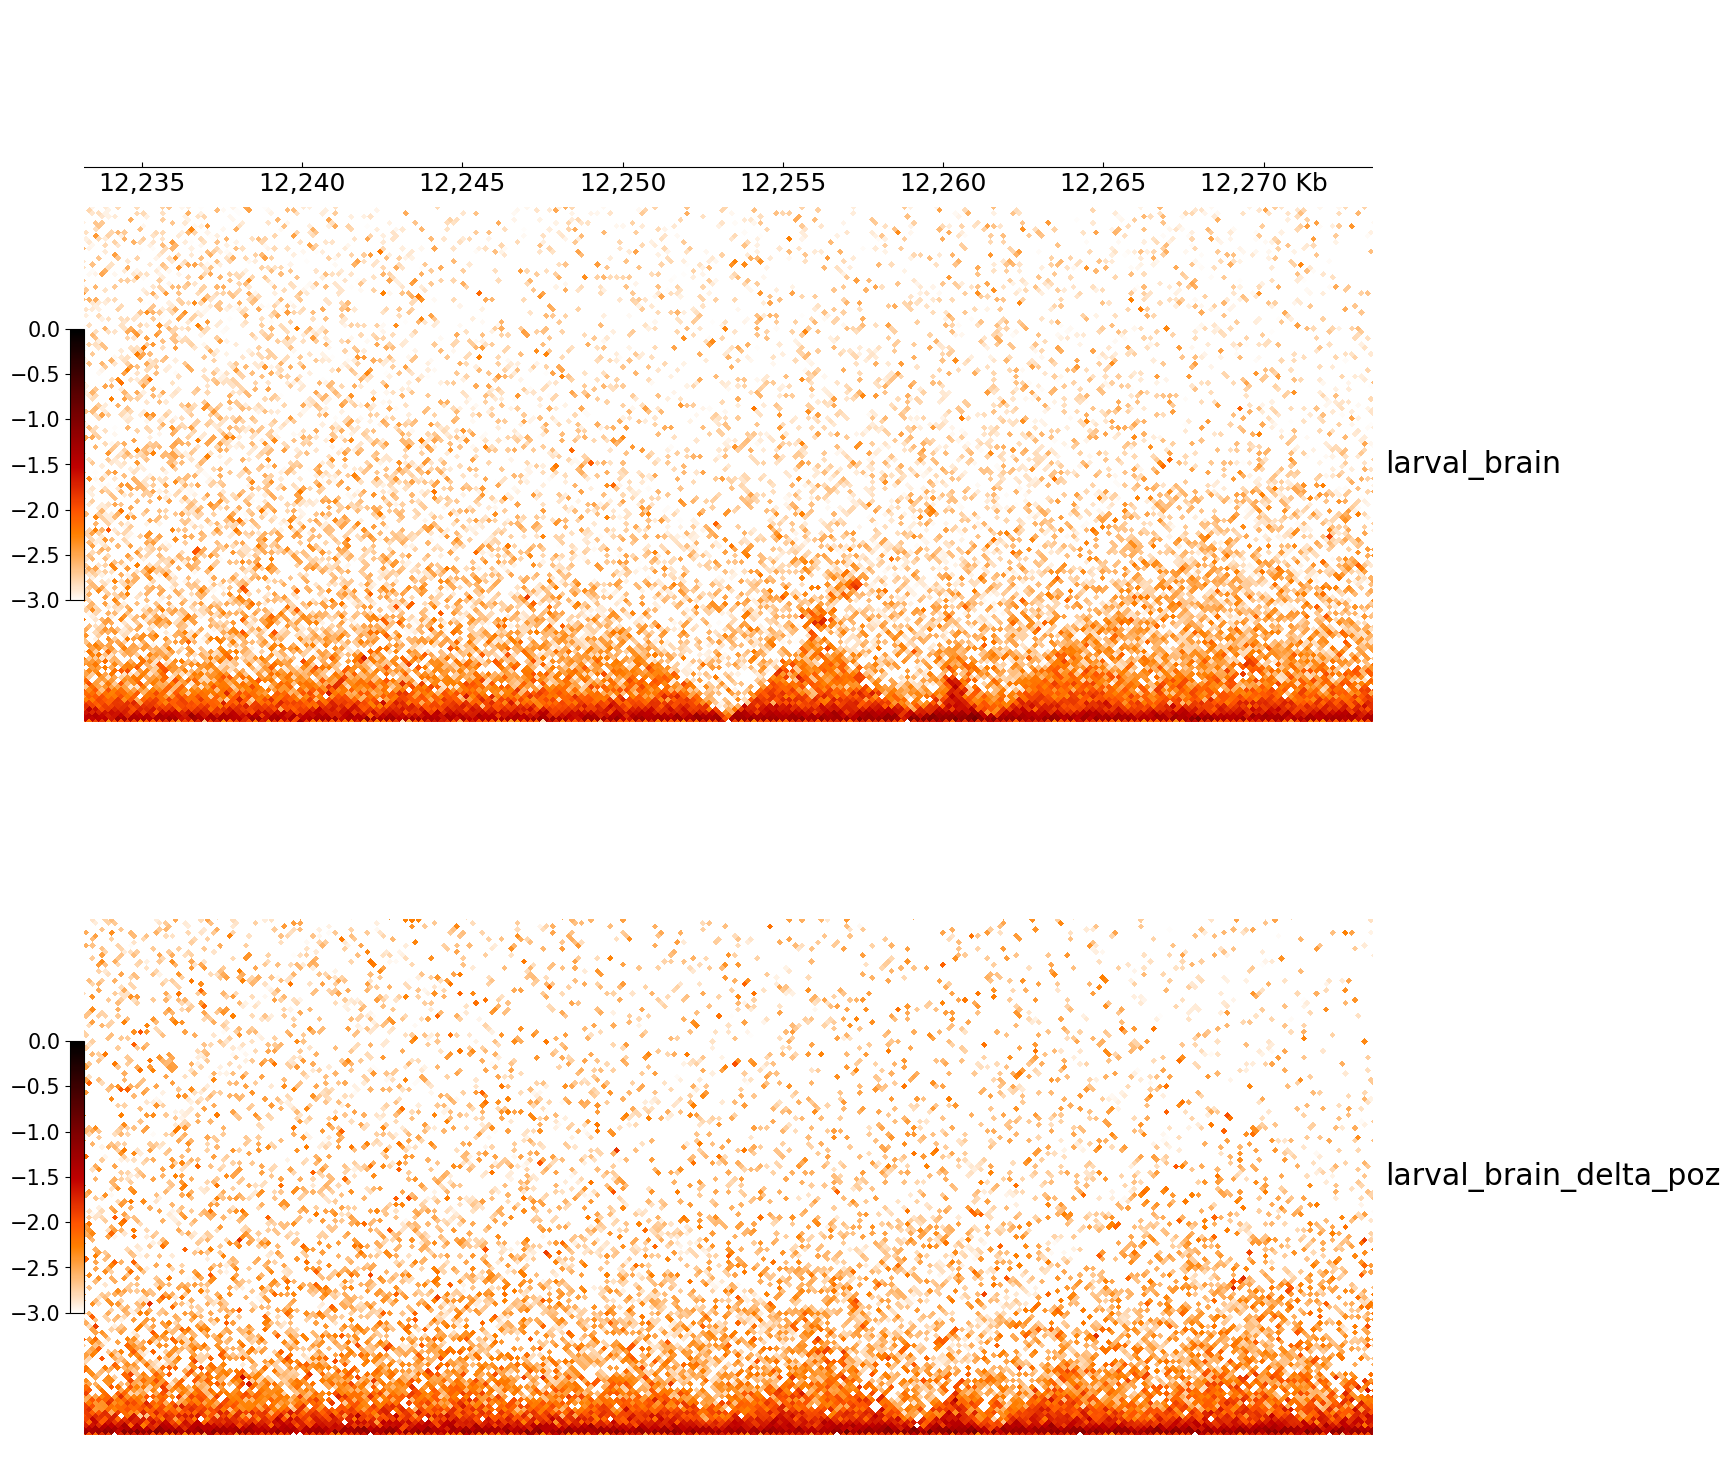

In [55]:

plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['font.size'] = 18

RESOLUTION=200
NUM_MERGED=11
OFFSET=20_000
# this is a GAGA boundary
chrom, start, end = ('chr2R', 12253201, 12253400)
print(chrom, start, end)

HIC_KWARGS = dict(
    style='window', 
    resolution=200, 
    depth_ratio=0.8, 
    cmap='gist_heat_r', 
    norm='no', 
    transform='log10', 
    max_value=0, 
    min_value=-3, 
    grid=False,
)

BEDGRAPH_KWARGS = dict(
    border_only=True,
    labels=False,
    num_rows=1,
    linewidth=4,
    height=1.5,
    style='line',
    line_width=2.5,
    alpha=0.5,
    border_color=None,
    properties=dict(fontsize=16),
)

BED_KWARGS = dict(
    border_only=False,
    labels=True,
    num_rows=1,
    linewidths=1,
    fontsize=1,
    height=1,
    properties=dict(line_width=1, fontsize=1, size=1),
    border_color=None,
    marker='.'
)

frame = []
frame.extend([coolbox.api.GTF('/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/annotations/Drosophila_melanogaster.BDGP6.54.115.gtf',
                                                    row_filter="type == 'gene';feature_name == 'Ae2'", color='black'), TrackHeight(3)])
frame.extend([coolbox.api.XAxis(fontsize=18, show_chrom=True)])
for tissue in tissue2mcool.keys():
    if 'larval_brain' not in tissue:
        continue
    frame.extend(
        [
            # Map
            coolbox.api.HiCMat(tissue2mcool[tissue], title=tissue, **HIC_KWARGS),
            coolbox.api.Spacer(), coolbox.api.TrackHeight(5),
        ]
    )
from functools import reduce
frame = frame[:-1]
frame = reduce(lambda x, y: x + y, frame)
fig = frame.plot(f"{chrom}:{start-OFFSET}-{end + OFFSET}")
fig.set(facecolor="white")
# fig.savefig("plots/wt_vs_delta_poz_boundary_example.pdf", format="pdf")
display(fig)

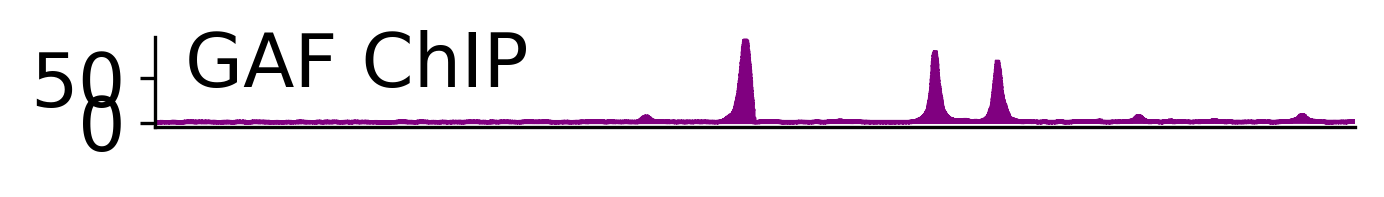

In [56]:
import bbi
rc, rs, re = chrom, start-OFFSET, end + OFFSET
fig, ax = init_subplots_exact(1,1, dpi=300, y_ratios=[0.075])

Trl_L3_bbi = bbi.open('/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/run_all_chip_seq/bigwig/Trl_L3_brain.bw')
plt.fill(np.arange(re-rs), Trl_L3_bbi.fetch(rc, rs, re), c='purple', rasterized=True)
plt.xlim(0, re-rs)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.tick_params(axis='x', which='both', bottom=False, top=False)
plt.xticks([])
ax.text(1000, 40, 'GAF ChIP')
plt.show()
# fig.savefig("plots/lb_GAGA_example_Trl_track.pdf", format="pdf", dpi=300, bbox_inches='tight')


## Scatterplot

In [58]:
ws = 1

larval_brain_ins_path = f'/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/insulations/insulation_files/new_larval_CNS_merged.resolution=200bp.insulation_{ws}kb.bed'
larval_brain_ins = process_bed_file_df(larval_brain_ins_path, 'ins_score')
larval_brain_delta_poz_ins_path = f'/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/insulations/insulation_files/larval_CNS_merged_delta_poz.resolution=200bp.insulation_{ws}kb.bed'
larval_brain_delta_poz_ins = process_bed_file_df(larval_brain_delta_poz_ins_path, 'ins_score')

# mean scaling - "." means it's NaN
mean_scaling_window=10
larval_brain_ins["demeaned_ins_score"] = larval_brain_ins["ins_score"] - larval_brain_ins["ins_score"].rolling(2*mean_scaling_window+1, center=True).mean()
larval_brain_delta_poz_ins["demeaned_ins_score"] = larval_brain_delta_poz_ins["ins_score"] - larval_brain_delta_poz_ins["ins_score"].rolling(2*mean_scaling_window+1, center=True).mean()

# get all larval boundaries with nonzero GAGA attribution
larval_GAGA_cluster = larval_boundaries.loc[larval_attributions[larval_attributions['GAGA'] < 0].index]
larval_GAGA_cluster['GAGA'] = larval_attributions.loc[larval_GAGA_cluster.index].GAGA

larval_brain_merged = larval_brain_ins.merge(larval_GAGA_cluster, on=['chrom','start','end'])
larval_brain_delta_poz_merged = larval_brain_delta_poz_ins.merge(larval_GAGA_cluster, on=['chrom','start','end'])
larval_GAGA_ins_combined_df = pd.DataFrame({
    'WT': larval_brain_merged.demeaned_ins_score.tolist(), 
    'POZ_deletion': larval_brain_delta_poz_merged.demeaned_ins_score.tolist(),
    'chrom': larval_brain_merged.chrom.tolist(),
    'start': larval_brain_merged.start.tolist(),
    'end': larval_brain_merged.end.tolist(),
    # 'num_active_motifs': larval_brain_merged.num_active_motifs.tolist(),
    'GAGA': larval_brain_merged.GAGA.tolist()
})
larval_GAGA_ins_combined_df = larval_GAGA_ins_combined_df.query('~WT.isnull() and ~POZ_deletion.isnull()')
print(larval_GAGA_ins_combined_df.shape)
larval_GAGA_ins_combined_df['delta'] = larval_GAGA_ins_combined_df.WT - larval_GAGA_ins_combined_df.POZ_deletion

(1023, 6)


T-statistic: -3.0296, P-value: 0.0012550831509341416


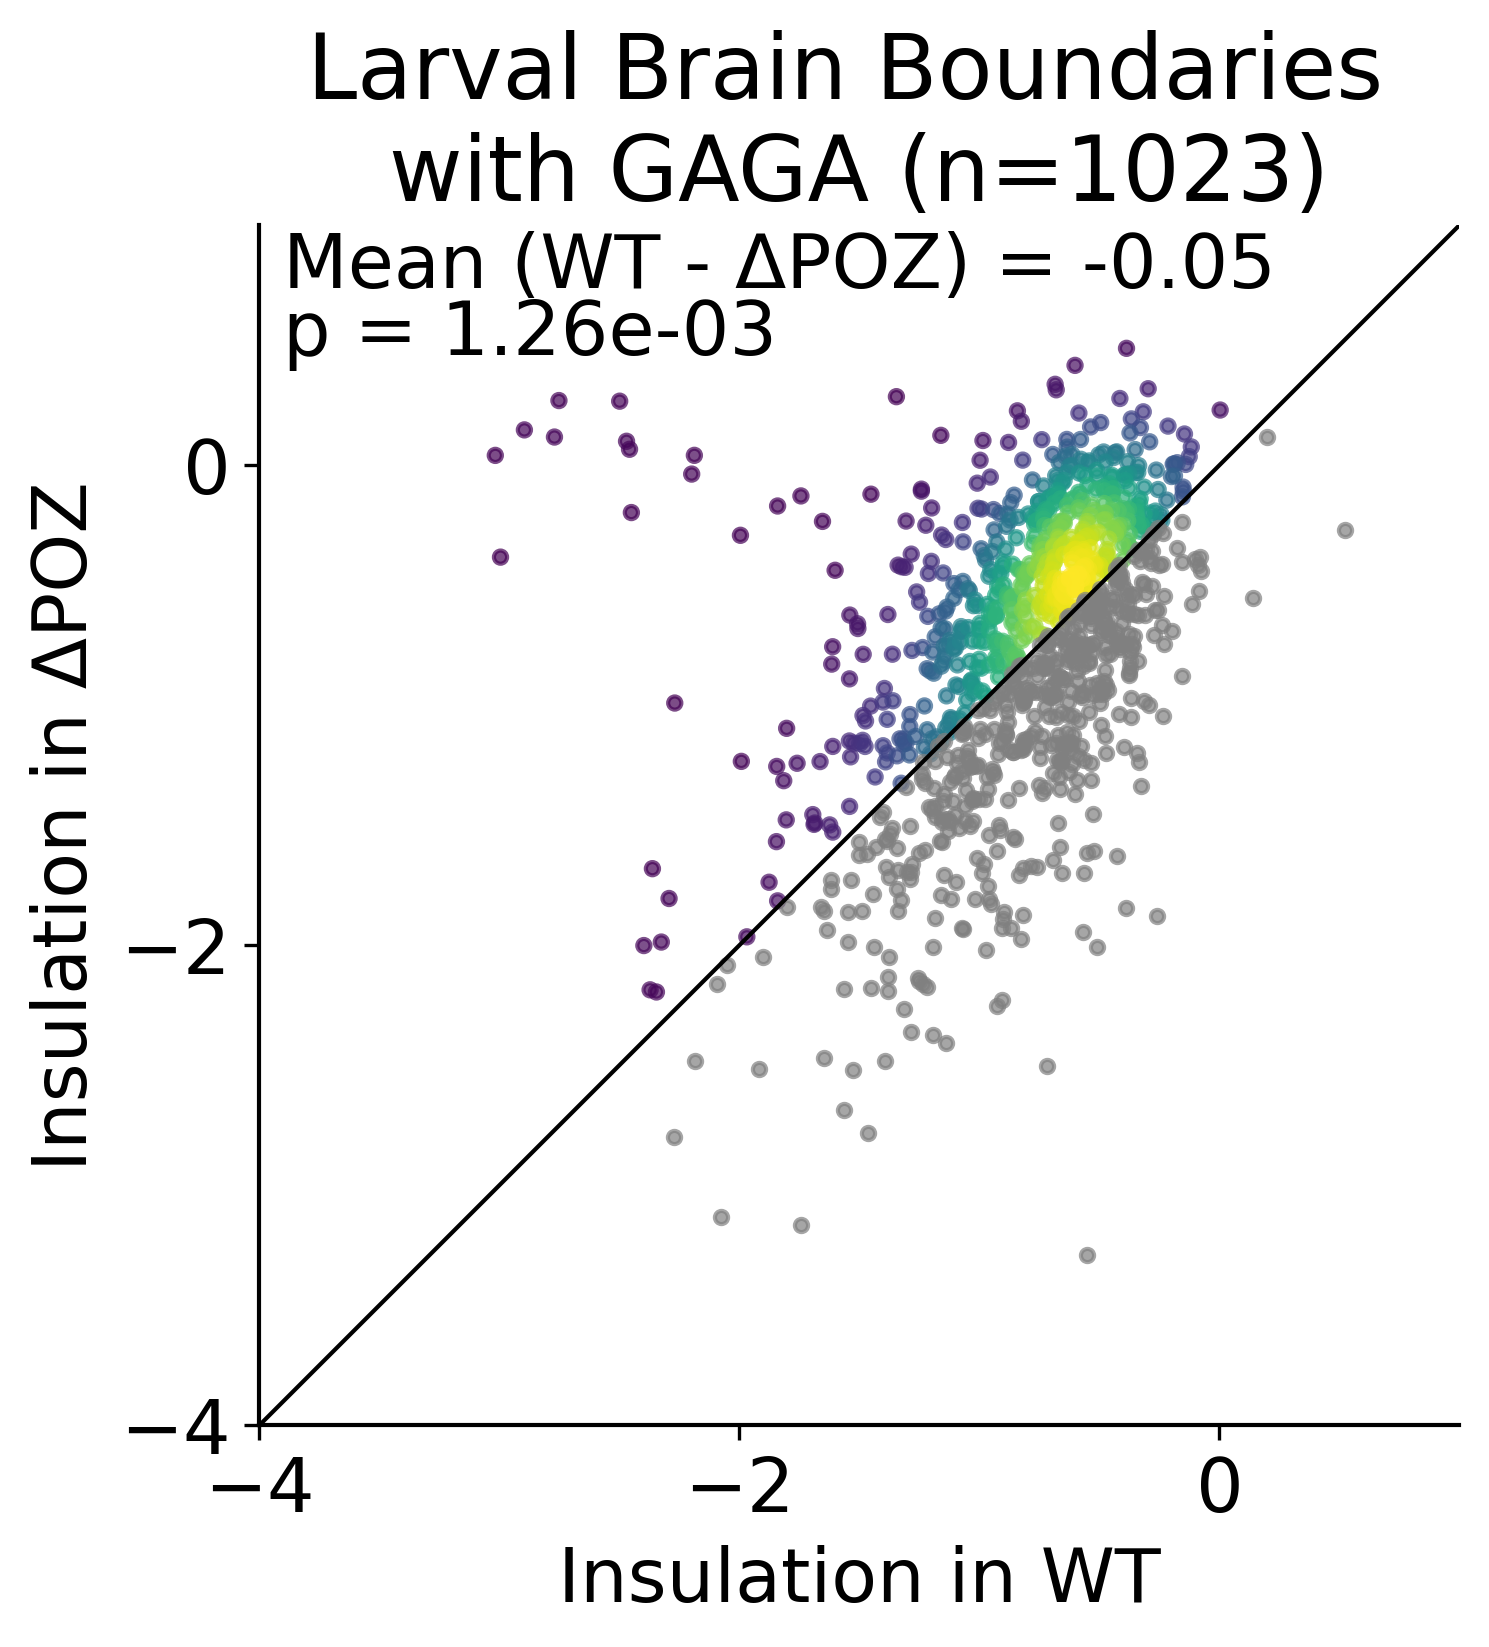

In [60]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import ttest_rel

t_stat, p_val = ttest_rel(larval_GAGA_ins_combined_df['WT'], larval_GAGA_ins_combined_df['POZ_deletion'], alternative='less')
print(f"T-statistic: {t_stat:.4f}, P-value: {p_val}")

x = larval_GAGA_ins_combined_df['WT'].values
y = larval_GAGA_ins_combined_df['POZ_deletion'].values

# mask
below = y < x

xy_all = np.vstack([x, y])
z_all = stats.gaussian_kde(xy_all)(xy_all)

# split
x_above = x[~below]
y_above = y[~below]
z_above = z_all[~below]

# sort for better visualization
idx = z_above.argsort()
x_above, y_above, z_above = x_above[idx], y_above[idx], z_above[idx]

fig, ax = init_subplots_exact(1,1, dpi=300)

ax.scatter(x_above, y_above, c=z_above, cmap='viridis', s=10, alpha=0.7)
ax.scatter(x[below], y[below], color='gray', s=10, alpha=0.7)
ax.plot([-4, 1], [-4, 1], c='black', lw=1)
ax.set_title(f'Larval Brain Boundaries \nwith GAGA (n={len(larval_GAGA_ins_combined_df)})')
ax.set_ylabel('Insulation in ΔPOZ')
ax.set_xlabel('Insulation in WT')

ax.set_xlim(-4, 1)
ax.set_ylim(-4, 1)

# ticks (reasonable spacing)
ticks = np.arange(-4, 1.1, 2)   # step = 1
ax.set_xticks(ticks)
ax.set_yticks(ticks)

ax.text(
    -3.9, 0.7,
    f"p = {p_val:.2e}",
    # transform=plt.gca().transAxes,
    ha='left',
    va='top'
)

ax.text(
    -3.9, 0.98,
    f"Mean (WT - ΔPOZ) = {np.mean(x-y):.2f}",
    # transform=plt.gca().transAxes,
    ha='left',
    va='top'
)

ax.spines[['right', 'top']].set_visible(False)
for spine in ['left', 'bottom']:  
        ax.spines[spine].set_color('black')  
        ax.spines[spine].set_linewidth(1)  # Decrease spine thickness

# fig.savefig("plots/wt_vs_delta_poz_scatterplot.pdf", format="pdf", bbox_inches='tight')
plt.show()

## Attribution with GAGA and Lola-N

In [61]:
X_attr = np.load('/scratch/gpfs/PRITYKIN/brendan/domino/output/02_27_2026_final_larval_brain/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/windowed_attributions.bound_score_gt_1.2.npy')

larval_model_dir = "/scratch/gpfs/PRITYKIN/brendan/domino/output/02_27_2026_final_larval_brain/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu"
all_larval_bound_df = pd.read_csv(f'{larval_model_dir}/final_boundaries_df.bound_score_gt_1.2.nan_offset=20000.stripe_offset=800.csv', index_col=0)
filtered_larval_boundaries_df = all_larval_bound_df.query('has_stripe_at_bound == False')

# filtered_larval_boundaries_df
X_attr_filtered = X_attr[filtered_larval_boundaries_df.index]
print(X_attr_filtered.shape[0]//2)

6919


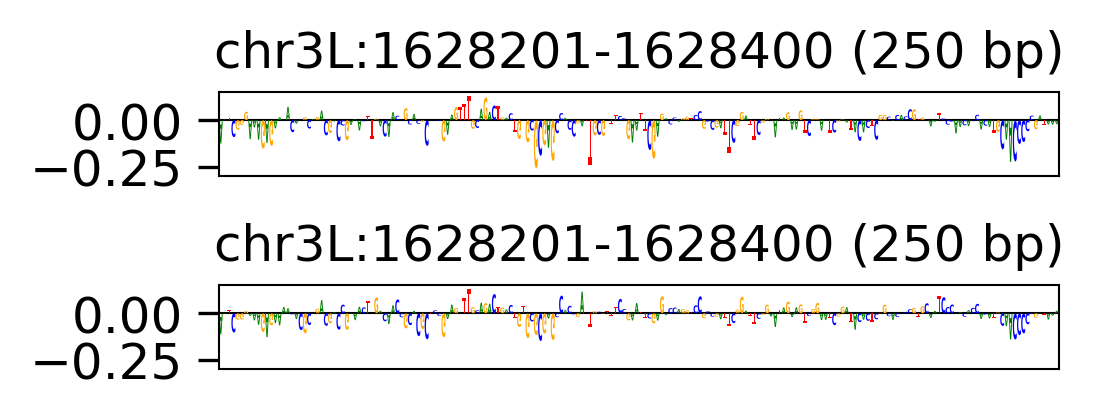

In [170]:
%matplotlib inline
from tangermeme.plot import plot_logo

plt.rcParams['font.size'] = 12

bound1 = larval_boundaries.loc[1368]
bound2 = larval_boundaries.loc[209]

bound1_attr = X_attr_filtered[1368 * 2 + 1][:, 100:300][::-1, ::-1] # on reverse strand but reverse complement to make on forward
bound2_attr = X_attr_filtered[1368 * 2][:, 300:500] # on reverse strand but reverse complement to make on forward

fig, axs = init_subplots_exact(2,2,dpi=300, y_ratios=[0.07] * 2, x_ratios=[0.7], yspace=2.3)
ax = axs[0]
plt.sca(axs[0])
logo = plot_logo(bound1_attr, ax=ax)
ax.grid(False)
ax.set_xticks([])
ax.set_xticklabels([])
# ax.set_xticks(np.arange(0, end-start+100, 100))
ax.tick_params(axis='both', which='both', length=5)  # Adjust tick length if needed

for spine in ax.spines.values():
    spine.set_visible(True)  
    spine.set_linewidth(0.5)  
    spine.set_edgecolor("black")  

plt.ylim([-0.3, 0.15])
chrom, start, end = bound1.chrom, bound1.start, bound1.end
plt.title(f'{chrom}:{start}-{end} (250 bp)', fontsize=12)


ax = axs[1]
plt.sca(axs[1])
logo = plot_logo(bound2_attr, ax=ax)
ax.grid(False)
ax.set_xticks([])
ax.set_xticklabels([])
# ax.set_xticks(np.arange(0, end-start+100, 100))
ax.tick_params(axis='both', which='both', length=5)  # Adjust tick length if needed

for spine in ax.spines.values():
    spine.set_visible(True)  
    spine.set_linewidth(0.5)  
    spine.set_edgecolor("black")  

plt.ylim([-0.3, 0.15])
chrom, start, end = bound1.chrom, bound1.start, bound1.end
plt.title(f'{chrom}:{start}-{end} (250 bp)', fontsize=12)

fig.savefig("plots/GAGA_lolaN_attributions.pdf", format="pdf", dpi=300, bbox_inches='tight')
plt.show()

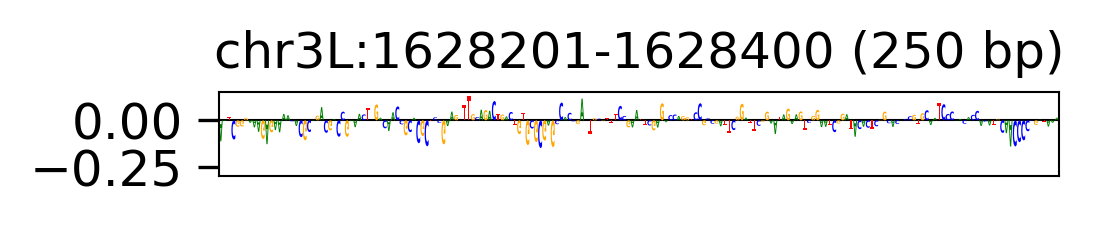

In [64]:
%matplotlib inline
from tangermeme.plot import plot_logo

plt.rcParams['font.size'] = 12

bound1 = larval_boundaries.loc[1368]

bound1_attr = X_attr_filtered[1368 * 2][:, 300:500] 

fig, ax = init_subplots_exact(1,1,dpi=300, y_ratios=[0.07], x_ratios=[0.7])
logo = plot_logo(bound1_attr, ax=ax)
ax.grid(False)
ax.set_xticks([])
ax.set_xticklabels([])
ax.tick_params(axis='both', which='both', length=5)  # Adjust tick length if needed

for spine in ax.spines.values():
    spine.set_visible(True)  
    spine.set_linewidth(0.5)  
    spine.set_edgecolor("black")  

plt.ylim([-0.3, 0.15])
chrom, start, end = bound1.chrom, bound1.start, bound1.end
plt.title(f'{chrom}:{start}-{end} (250 bp)', fontsize=12)

# fig.savefig("plots/GAGA_lolaN_attributions.pdf", format="pdf", dpi=300, bbox_inches='tight')
plt.show()

[ERROR:tab.py:300 -                query()] Reference sequence chr3L not found in index header.


chr3L 1628201 1628400


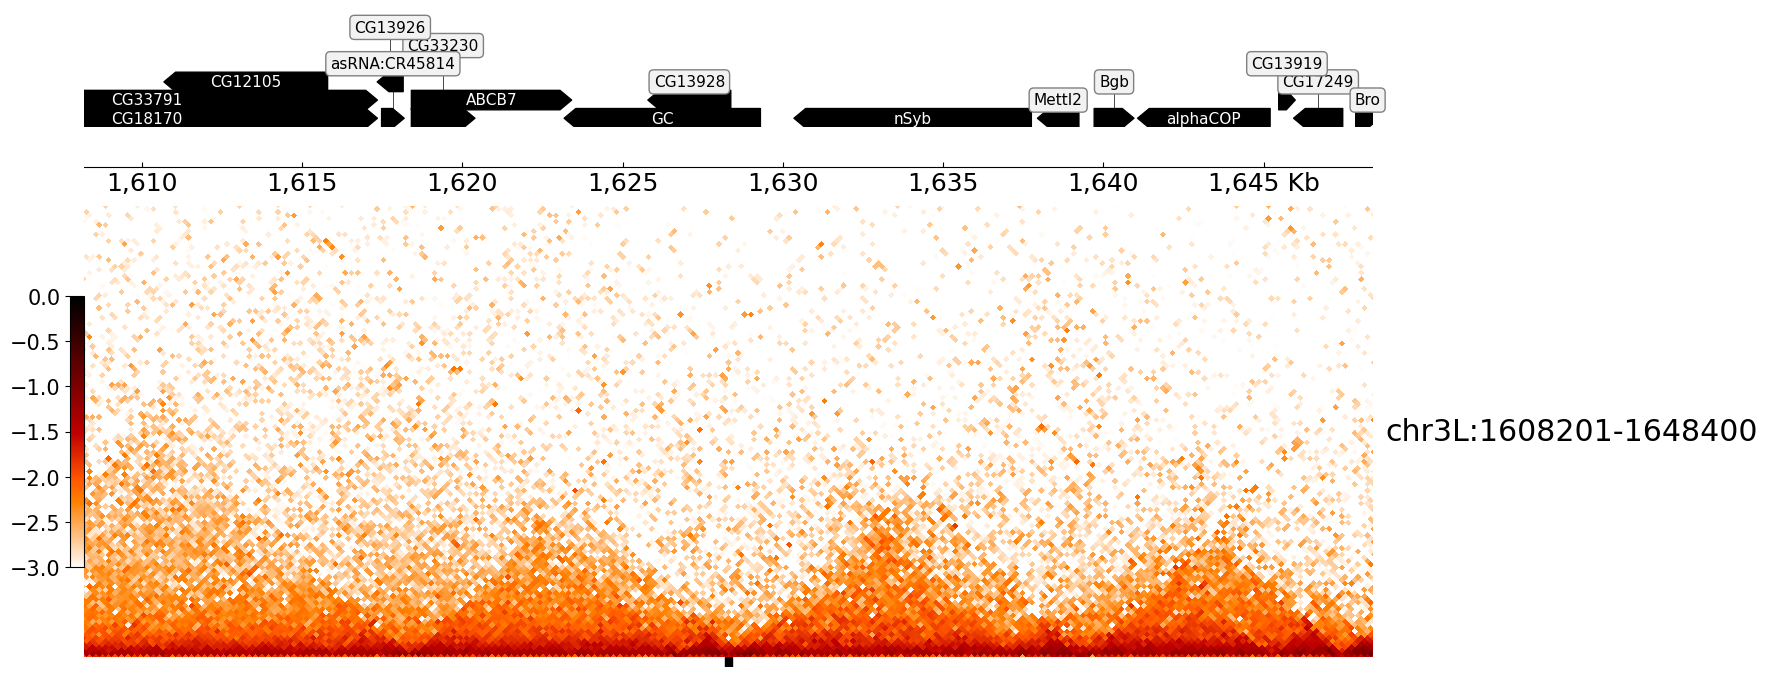

In [65]:
row = bound1

plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['font.size'] = 18

RESOLUTION=200
NUM_MERGED=11
OFFSET=20_000
# this is a GAGA boundary
chrom, start, end = row.chrom, row.start, row.end
print(chrom, start, end)

HIC_KWARGS = dict(
    style='window', 
    resolution=200, 
    depth_ratio=0.7, 
    cmap='gist_heat_r', 
    norm='no', 
    transform='log10', 
    max_value=0, 
    min_value=-3, 
    grid=False,
)


frame = []
frame.extend([coolbox.api.GTF('/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/annotations/Drosophila_melanogaster.BDGP6.54.115.gtf',
                                                    row_filter="type == 'gene'", color='#000000'), TrackHeight(3)])
frame.extend([coolbox.api.XAxis(fontsize=18, show_chrom=True)])
frame.extend(
    [
        # Map
        coolbox.api.HiCMat(tissue2mcool['larval_brain'], title=f"{chrom}:{start-OFFSET}-{end + OFFSET}", **HIC_KWARGS),
        coolbox.api.Spacer(), coolbox.api.TrackHeight(0.25),
        
        coolbox.core.coverage.HighLights(f'{chrom}:{start}-{end}', color='black', alpha=1),
        coolbox.api.TrackHeight(0.25),
    ]
)
from functools import reduce
frame = frame[:-1]
frame = reduce(lambda x, y: x + y, frame)
fig = frame.plot(f"{chrom}:{start-OFFSET}-{end + OFFSET}")
fig.set(facecolor="white")
# fig.savefig("plots/GAGA_lolaN_boundary_example.pdf", format="pdf")
display(fig)